In [1]:
!pip install anndata=='0.8.0'

In [2]:
!pip install openpyxl

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 251.3/251.3 kB 3.5 MB/s eta 0:00:0000:01


In [2]:
from samap.mapping import SAMAP
from samap.analysis import (get_mapping_scores, GenePairFinder, transfer_annotations,
                            sankey_plot, chord_plot, CellTypeTriangles, 
                            ParalogSubstitutions, FunctionalEnrichment,
                            convert_eggnog_to_homologs, GeneTriangles)
from samalg import SAM
import pandas as pd
from samap.utils import (save_samap, load_samap)
import scanpy as sc
import matplotlib.colors
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import time
import dill
import matplotlib.cm as cm
from matplotlib import colors
from sklearn.manifold import TSNE
from statistics import mode
import pickle
from scipy import stats

/scratch/miniconda/lib/python3.7/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
fn = 'Active_SAM_joined/SAM_RI_joined_soupx_cleaned_01142026.h5ad'

sam=SAM()
sam.load_data(fn)
gene_dict = {}
for i in range(len(sam.adata.var_names)):
    gene_dict[sam.adata.var_names[i]]= i

In [ ]:
#Finding gene

In [4]:
m = pd.read_csv('BLASTMAPPING/maps/active_maps/Monogamous_proj_v2/mgri/mg_to_ri.txt', delimiter = '\t', header = None)

In [5]:
m[m[0] == 'Penk']

,0,1,2,3,4,5,6,7,8,9,10,11
264988,Penk,PENK,58.763,97,40,0,451,741,1056,1346,1.980000e-87,150.0
264989,Penk,PDYN,33.333,60,40,0,595,774,1205,1384,1.790000e-13,46.0
264990,Penk,PNOC,33.846,65,43,0,52,246,219,413,3.820000e-13,57.9


In [6]:
common_name = 'Penk'
try:
    gn = 'PENK'
    gi = gene_dict[gn]
except:
    print('not in genome')

In [778]:
#Range of Gene Expression

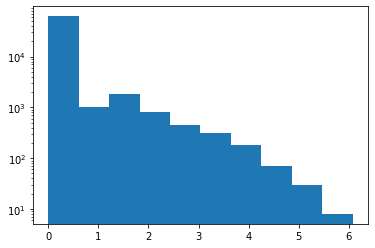

In [7]:
plt.hist(sam.adata.X[:,gi].A)
plt.yscale('log')

In [1595]:
#Plot gene expression

In [27]:
vmin = 1.5
vmax = 5

In [28]:
subexp = sam.adata[sam.adata.X[:,gi] > vmin]

In [29]:
subexp

View of AnnData object with n_obs × n_vars = 2660 × 23867
    obs: 'n_genes', 'n_counts', 'key', 'leiden_clusters', 'subclass_id_label_mapping', 'subclass_id_label_lc', 'subclass_id_label_mapping_nounlabeled', 'subclass_id_label_crossed', 'subclass_id_label_crossed_nn', 'subclass_lc', 'ss_subclass', 'ss_subclass_nn', 'ss_subclass_nounlabeled_nn', 'ss_subclass_crossed_nn', 'ss_subclass_nounlabeled_nn_agrp', 'yanay_labels', 'yanay_label_nounlabeled', 'ss_subclass_old', 'n_counts_cl', 'n_genes_cl', 'ss_subclass_v5_nounlabeled'
    var: 'mask_genes', 'means', 'variances', 'weights', 'spatial_dispersions'
    uns: 'dimred_indices', 'path_to_file', 'preprocess_args', 'ranked_genes', 'run_args'
    obsm: 'Raw_X', 'X_pca', 'X_processed', 'X_tsne', 'X_umap'
    varm: 'PCs'
    layers: 'X_disp'
    obsp: 'connectivities', 'distances', 'nnm'

In [30]:
scalar_mappable = cm.ScalarMappable(cmap='viridis', norm=colors.Normalize(vmin=vmin, vmax=vmax))

In [31]:
organism = 'Imitator_Frog'

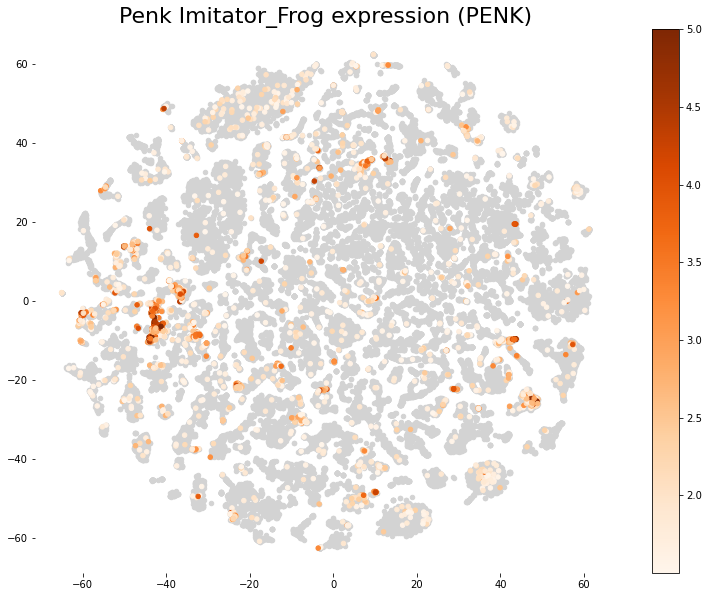

In [33]:
save_figure = True

plt.figure(figsize = (13,10))
plt.scatter(sam.adata.obsm['X_tsne'][:,0],sam.adata.obsm['X_tsne'][:,1], c = 'lightgrey',s=20)
plt.scatter(subexp.obsm['X_tsne'][:,0],subexp.obsm['X_tsne'][:,1], c = subexp.X[:,gi].A,s=20,cmap = 'Oranges', vmax = vmax)
plt.title(common_name + ' ' + organism + ' expression' + ' (' + gn + ')', fontsize = 22)
plt.box(False)
plt.colorbar()
if save_figure:
    plt.savefig('Figures/Figures_10012026/' + organism + '_' + common_name + '_10012026.png', dpi = 300, bbox_inches = 'tight')
    #plt.savefig('Figures/Figures_025/Billie_Data/' + organism + '_' + common_name + '_lowthresh.svg')
    #plt.savefig('Figures/\Figures_1172025/Billie_Data/' + organism + '_' + common_name + '_lowthresh.pdf')

In [34]:
level = 'ss_subclass_v5_nounlabeled'

In [35]:
agrp_positive = sam.adata.obs_names[sam.adata.obs[level].isin(['106 PVpo-VMPO-MPN Hmx2 Gaba'])]

In [36]:
len(agrp_positive)

1250

In [37]:
agrp_label = []
lc_label = {}
for item in sam.adata.obs_names:
    if item in agrp_positive:
        if sam.adata.obs.loc[item, level] in lc_label.keys():
            lc_label[sam.adata.obs.loc[item, level]] += 1
        else:
            lc_label[sam.adata.obs.loc[item, level]] = 1
        agrp_label.append('1')
    else:
        agrp_label.append('0')

In [38]:
lc_label

{'106 PVpo-VMPO-MPN Hmx2 Gaba': 1250}

In [39]:
sam.adata.obs['test'] = agrp_label

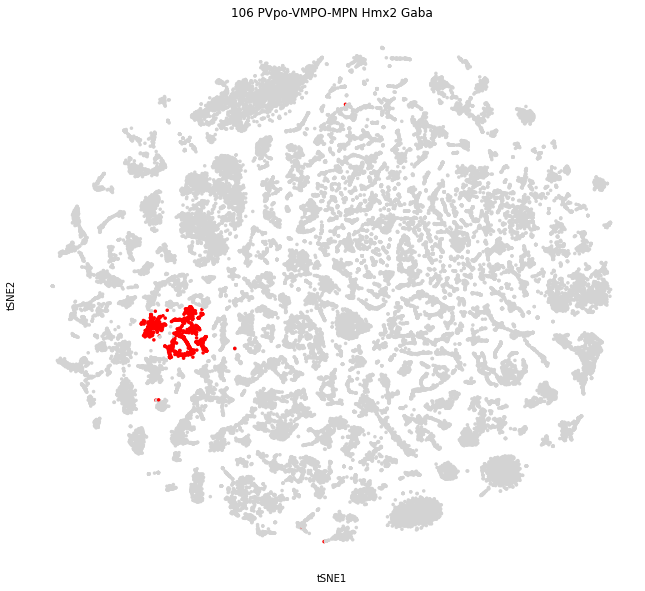

In [43]:
plt.rcParams["figure.figsize"] = (11,10)

g = sc.pl.tsne(sam.adata, color = 'test', s=50, palette = ['lightgrey','red'], legend_loc = 'none', title = '106 PVpo-VMPO-MPN Hmx2 Gaba', return_fig = True)
plt.box(False)
g.savefig('Figures/Figures_10012026/RI_106_10012026.png',dpi = 300, bbox_inches = 'tight')
#plt.show()
#matplotlib.rcParams.update(matplotlib.rcParamsDefault)